# ASCENT 4-130, Module 2 : Concept des agents intelligents et interactions avec l'environnement

**Formation** : Les agents autonomes et aide à la décision (Jour 1, module 2, 2 heures).

**Objectifs du module**

- Définir un agent intelligent et ses caractéristiques.
- Modéliser l'interaction avec l'environnement par des capteurs et des effecteurs.
- Distinguer l'état réel de l'environnement et ce que l'agent en observe.
- Relier ces notions à des applications en robotique et en domotique.

**Fil rouge** : le robot de l'entrepôt logistique perçoit son voisinage avec un lidar à 8 rayons et se déplace d'une cellule à la fois. Nous construisons sa boucle perception, décision, action pas à pas.

**Travaux pratiques du syllabus** : simuler les interactions d'un agent avec son environnement dans un scénario donné.

| Partie | Contenu | Durée indicative |
|---|---|---|
| 1 | Un agent en dix lignes : le thermostat (domotique) | 10 min |
| 2 | Construire un environnement à la main | 15 min |
| 3 | L'entrepôt simulé : capteurs, effecteurs, boucle pas à pas | 15 min |
| 4 | État réel et état observé | 15 min |
| 5 | Un environnement qui change : chariots et imprévus | 10 min |
| 6 | La trace, format commun de rejeu | 10 min |

Ce module ne contient aucun calcul tensoriel : la simulation d'un seul agent est séquentielle et s'exécute sur CPU. Le GPU reviendra au Jour 2 pour simuler des milliers d'environnements en parallèle.

In [1]:
# Installation automatique (Colab ou poste sans le paquet). Sans effet si tout est déjà installé.
import importlib.util, subprocess, sys
if importlib.util.find_spec("ascent_agents") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ascent-agents[complet] @ https://martinobettucci.github.io/4-120/dist/ascent_agents-1.0.0-py3-none-any.whl"])

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ascent_agents import ACTIONS, creer_scenario, detecter_appareil, fixer_graines, lister_scenarios, simuler
from ascent_agents.monde import RAYONS, Evenement
from ascent_agents.traces import charger_trace
from ascent_agents.visualisation import BLEU, GRIS, JAUNE, NOIR, ROUGE, VERT, dessiner_monde, dessiner_trace, style

APPAREIL = detecter_appareil()   # affiché pour information : ce module reste sur CPU
fixer_graines(4130)
style()
RESULTATS = Path("resultats")
RESULTATS.mkdir(exist_ok=True)

Aucun GPU CUDA detecte : repli sur CPU (tous les notebooks restent executables).
PyTorch 2.15.0+cpu


## 1. Un agent en dix lignes : le thermostat

Un **agent** est un système qui perçoit son environnement par des capteurs, décide, puis agit sur cet environnement par des effecteurs, de façon répétée, pour atteindre un objectif. La définition couvre un thermostat comme un robot.

| | Thermostat (domotique) | Robot d'entrepôt (robotique) |
|---|---|---|
| Objectif | Température proche de la consigne | Atteindre le point de livraison sans collision |
| Environnement | Une pièce, la météo | L'entrepôt, les chariots, les palettes |
| Capteurs | Sonde de température | Lidar, localisation |
| Effecteurs | Relais du chauffage | Moteurs des roues |
| Décision | Deux règles | Règles, plan ou politique apprise |

La boucle ci-dessous contient déjà tout : l'environnement a un état réel (la température de la pièce), l'agent n'en voit qu'une mesure bruitée, et son action modifie l'état suivant.

Nombre de commutations du relais : 40


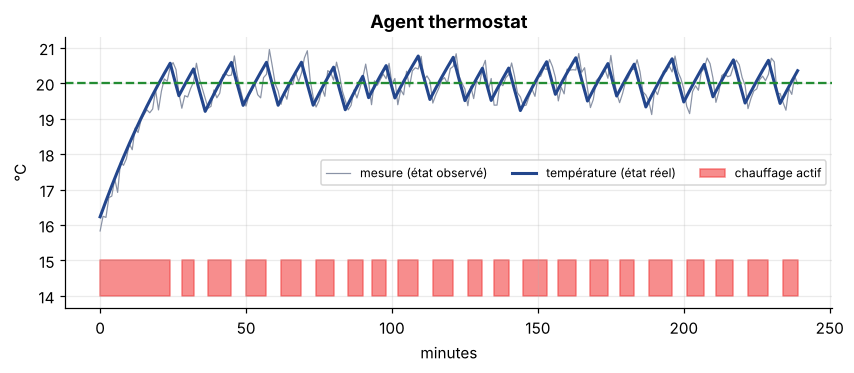

In [3]:
PARAMETRES_THERMOSTAT = {
    "consigne": 20.0,        # °C
    "hysteresis": 0.5,       # marge autour de la consigne avant de commuter
    "bruit_sonde": 0.2,      # écart type du bruit de mesure, en °C
    "exterieur": 5.0,        # température extérieure
    "minutes": 240,
}


def simuler_thermostat(p, graine=4130):
    rng = np.random.default_rng(graine)
    temperature, chauffage = 16.0, False
    historique = []
    for minute in range(p["minutes"]):
        mesure = temperature + rng.normal(0, p["bruit_sonde"])             # PERCEPTION (capteur bruité)
        if mesure < p["consigne"] - p["hysteresis"]:                      # DÉCISION (deux règles)
            chauffage = True
        elif mesure > p["consigne"] + p["hysteresis"]:
            chauffage = False
        # ACTION et dynamique de l'environnement : pertes vers l'extérieur, apport du radiateur.
        temperature += 0.02 * (p["exterieur"] - temperature) + (0.45 if chauffage else 0.0)
        historique.append((minute, temperature, mesure, chauffage))
    return pd.DataFrame(historique, columns=["minute", "temperature", "mesure", "chauffage"])


h = simuler_thermostat(PARAMETRES_THERMOSTAT)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(h["minute"], h["mesure"], color=GRIS, lw=0.8, label="mesure (état observé)")
ax.plot(h["minute"], h["temperature"], color=BLEU, lw=2, label="température (état réel)")
ax.fill_between(h["minute"], 14, 15, where=h["chauffage"], color=ROUGE, alpha=0.6, label="chauffage actif")
ax.axhline(PARAMETRES_THERMOSTAT["consigne"], color=VERT, ls="--")
ax.set(xlabel="minutes", ylabel="°C", title="Agent thermostat")
ax.legend(ncol=3, fontsize=8)
print("Nombre de commutations du relais :", int(h["chauffage"].astype(int).diff().abs().sum()))

### Exercice 1 : le rôle de l'hystérésis

Passez `hysteresis` à 0 puis à 1,5. Observez le nombre de commutations du relais (usure de l'effecteur) et l'amplitude des oscillations (confort). Augmentez ensuite `bruit_sonde` à 0,6 avec une hystérésis nulle : que constate-t-on ?

In [4]:
# À COMPLÉTER : modifiez les valeurs.
essai = {**PARAMETRES_THERMOSTAT, "hysteresis": 0.5, "bruit_sonde": 0.2}
h = simuler_thermostat(essai)
print("Commutations :", int(h["chauffage"].astype(int).diff().abs().sum()), "| amplitude après 60 min :", round(h["temperature"][60:].max() - h["temperature"][60:].min(), 2), "°C")

Commutations : 40 | amplitude après 60 min : 1.54 °C


In [5]:
# Solution possible : balayage des deux paramètres.
lignes = []
for hyst in (0.0, 0.5, 1.5):
    for bruit in (0.2, 0.6):
        h = simuler_thermostat({**PARAMETRES_THERMOSTAT, "hysteresis": hyst, "bruit_sonde": bruit})
        lignes.append({"hystérésis": hyst, "bruit sonde": bruit,
                       "commutations": int(h["chauffage"].astype(int).diff().abs().sum()),
                       "amplitude (°C)": round(h["temperature"][60:].max() - h["temperature"][60:].min(), 2)})
pd.DataFrame(lignes)

,hystérésis,bruit sonde,commutations,amplitude (°C)
0,0.0,0.2,130,0.86
1,0.0,0.6,118,1.17
2,0.5,0.2,40,1.54
3,0.5,0.6,60,1.98
4,1.5,0.2,14,3.34
5,1.5,0.6,19,3.27


Sans hystérésis, le bruit de mesure fait commuter le relais en permanence : l'agent réagit à ses propres erreurs de perception. Une marge réduit les commutations au prix d'oscillations plus amples. Ce compromis entre réactivité et stabilité se retrouve dans tous les agents.

## 2. Construire un environnement à la main

Avant d'utiliser l'entrepôt du paquet, écrivons un environnement minimal pour voir ce qu'il doit fournir : un **état**, une fonction de **perception** (ce que l'agent reçoit) et une fonction de **transition** (l'effet d'une action).

In [6]:
PLAN_MINI = [
    "########",
    "#D..#..#",
    "#.#.#.##",
    "#.#...A#",
    "########",
]
DEPLACEMENTS = {"N": (0, -1), "E": (1, 0), "S": (0, 1), "O": (-1, 0)}


class MiniMonde:
    """Environnement minimal : une grille, un robot, un objectif."""

    def __init__(self, plan):
        self.plan = plan
        for y, ligne in enumerate(plan):
            for x, c in enumerate(ligne):
                if c == "D":
                    self.depart = (x, y)
                if c == "A":
                    self.objectif = (x, y)
        self.robot = self.depart

    def libre(self, cellule):
        x, y = cellule
        return self.plan[y][x] != "#"

    def percevoir(self):
        """Observation : pour chaque direction, la cellule voisine est-elle libre ? Plus le cap vers l'objectif."""
        x, y = self.robot
        voisinage = {a: self.libre((x + dx, y + dy)) for a, (dx, dy) in DEPLACEMENTS.items()}
        return {"libre": voisinage, "cap": (self.objectif[0] - x, self.objectif[1] - y)}

    def agir(self, action):
        """Transition : déplace le robot si la cellule visée est libre. Retourne True à l'arrivée."""
        dx, dy = DEPLACEMENTS[action]
        cible = (self.robot[0] + dx, self.robot[1] + dy)
        if self.libre(cible):
            self.robot = cible
        return self.robot == self.objectif

    def afficher(self):
        for y, ligne in enumerate(self.plan):
            print("".join("R" if (x, y) == self.robot else c for x, c in enumerate(ligne)))


def agent_aleatoire(observation, rng):
    """Choisit au hasard parmi les directions libres : aucune notion d'objectif."""
    return rng.choice([a for a, ok in observation["libre"].items() if ok])


monde = MiniMonde(PLAN_MINI)
rng = np.random.default_rng(1)
monde.afficher()
for etape in range(1, 200):
    observation = monde.percevoir()            # perception
    action = agent_aleatoire(observation, rng)  # décision
    if monde.agir(action):                      # action
        break
print(f"\nObjectif atteint en {etape} étapes par l'agent aléatoire.")

########
#R..#..#
#.#.#.##
#.#...A#
########

Objectif atteint en 91 étapes par l'agent aléatoire.


L'agent aléatoire finit par arriver, sans aucune intelligence : il n'exploite pas la moitié de son observation (le cap vers l'objectif).

### Exercice 2 : un agent qui utilise son observation

Écrivez `agent_glouton(observation, rng)` : il choisit une direction libre qui le rapproche de l'objectif, et à défaut une direction libre au hasard. Comparez le nombre moyen d'étapes sur 200 essais avec l'agent aléatoire.

In [7]:
def mesurer(agent, essais=200, limite=500):
    """Nombre d'étapes par essai (limite si l'objectif n'est pas atteint)."""
    durees = []
    for graine in range(essais):
        monde, rng = MiniMonde(PLAN_MINI), np.random.default_rng(graine)
        for etape in range(1, limite + 1):
            if monde.agir(agent(monde.percevoir(), rng)):
                break
        durees.append(etape)
    return np.array(durees)


# À COMPLÉTER : pour l'instant, votre agent se comporte comme l'agent aléatoire.
def agent_glouton(observation, rng):
    return agent_aleatoire(observation, rng)


print(f"Aléatoire : {mesurer(agent_aleatoire).mean():.1f} étapes en moyenne")
print(f"Le vôtre  : {mesurer(agent_glouton).mean():.1f} étapes en moyenne")

Aléatoire : 78.7 étapes en moyenne


Le vôtre  : 78.7 étapes en moyenne


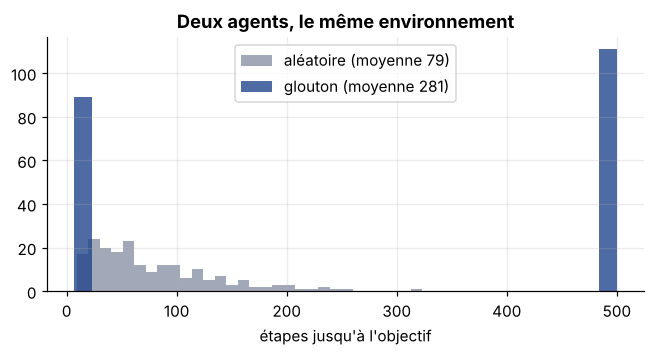

In [8]:
# Solution possible.
def agent_glouton_solution(observation, rng):
    dx, dy = observation["cap"]
    souhaits = []
    if dx != 0:
        souhaits.append("E" if dx > 0 else "O")
    if dy != 0:
        souhaits.append("S" if dy > 0 else "N")
    utiles = [a for a in souhaits if observation["libre"][a]]
    if utiles:
        return rng.choice(utiles)
    return agent_aleatoire(observation, rng)


d_alea, d_glouton = mesurer(agent_aleatoire), mesurer(agent_glouton_solution)
plt.figure(figsize=(7, 3))
plt.hist(d_alea, bins=30, color=GRIS, alpha=0.8, label=f"aléatoire (moyenne {d_alea.mean():.0f})")
plt.hist(d_glouton, bins=30, color=BLEU, alpha=0.8, label=f"glouton (moyenne {d_glouton.mean():.0f})")
plt.xlabel("étapes jusqu'à l'objectif")
plt.title("Deux agents, le même environnement")
plt.legend();

## 3. L'entrepôt simulé : capteurs, effecteurs, boucle pas à pas

Le paquet `ascent_agents` fournit le même contrat que notre mini monde, en plus riche : `observer()` pour la perception, `avancer(action)` pour la transition. Trois scénarios sont disponibles.

{'entrepot': 'Entrepot de reference', 'ouvert': 'Zone degagee', 'piege': 'Cul-de-sac en U'}


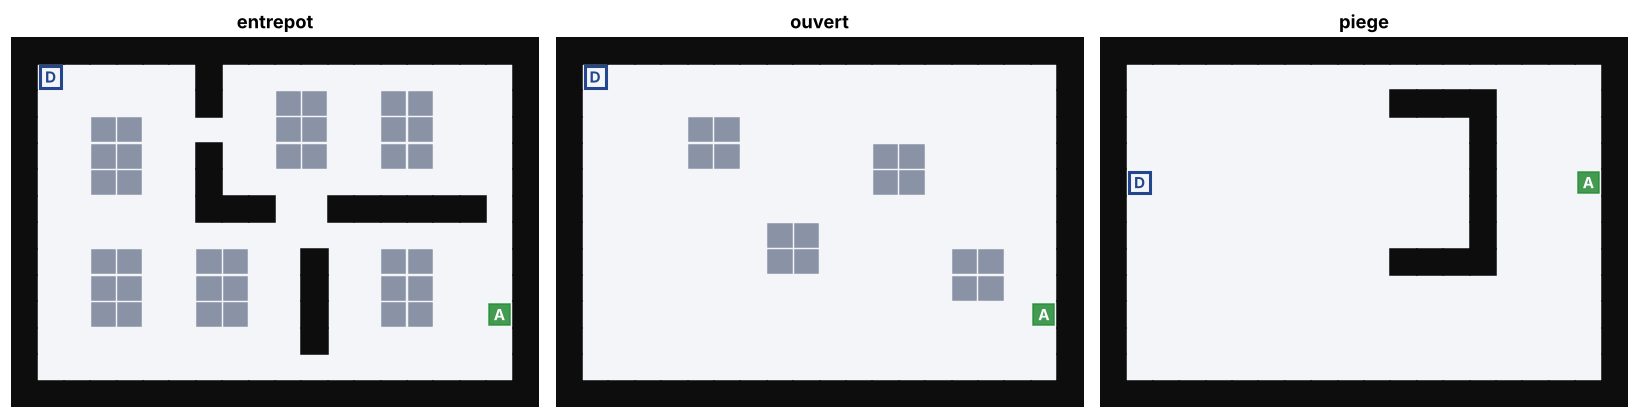

In [9]:
print(lister_scenarios())
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, nom in zip(axes, lister_scenarios()):
    dessiner_monde(creer_scenario(nom), ax, titre=nom)
plt.tight_layout()

**Capteurs.** Le lidar mesure, sur 8 rayons, la distance en cellules au premier obstacle (1 signifie cellule voisine occupée, portée 5, la valeur 6 signifie rien dans la portée). L'observation contient aussi la position mesurée et le cap vers l'objectif.

**Effecteurs.** Cinq actions : `N`, `E`, `S`, `O` et `ATTENDRE`.

Actions possibles : ['N', 'E', 'S', 'O', 'ATTENDRE']
Observation initiale :
  etape         0
  lidar         {'N': 1, 'NE': 1, 'E': 6, 'SE': 2, 'S': 6, 'SO': 1, 'O': 1, 'NO': 1}
  position      (1, 1)
  objectif      (18, 10)
  cap_objectif  (17, 9)


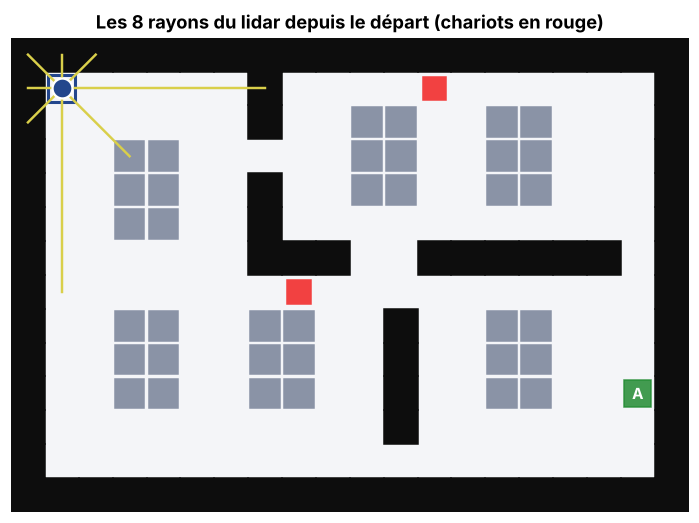

In [10]:
monde = creer_scenario("entrepot")
observation = monde.reinitialiser()
print("Actions possibles :", list(ACTIONS))
print("Observation initiale :")
for cle, valeur in observation.items():
    print(f"  {cle:13s} {valeur}")
dessiner_monde(monde, robot=monde.robot, lidar=observation["lidar"], obstacles=monde.obstacles_dynamiques(),
               titre="Les 8 rayons du lidar depuis le départ (chariots en rouge)");

### Un agent simple et sa boucle, écrite en clair

L'agent ci-dessous respecte l'interface commune de la formation : `reinitialiser(monde)` puis `decider(observation)`, qui retourne l'action et un dictionnaire d'informations expliquant la décision.

t=0  action=E        robot=(2, 1)  collision=False  (voie libre vers l'objectif : E)
t=1  action=E        robot=(3, 1)  collision=False  (voie libre vers l'objectif : E)
t=2  action=E        robot=(4, 1)  collision=False  (voie libre vers l'objectif : E)
t=3  action=E        robot=(5, 1)  collision=False  (voie libre vers l'objectif : E)
t=4  action=E        robot=(6, 1)  collision=False  (voie libre vers l'objectif : E)
t=5  action=E        robot=(7, 1)  collision=False  (voie libre vers l'objectif : E)
...
Arrivé : True en 26 étapes, 0 collision(s).


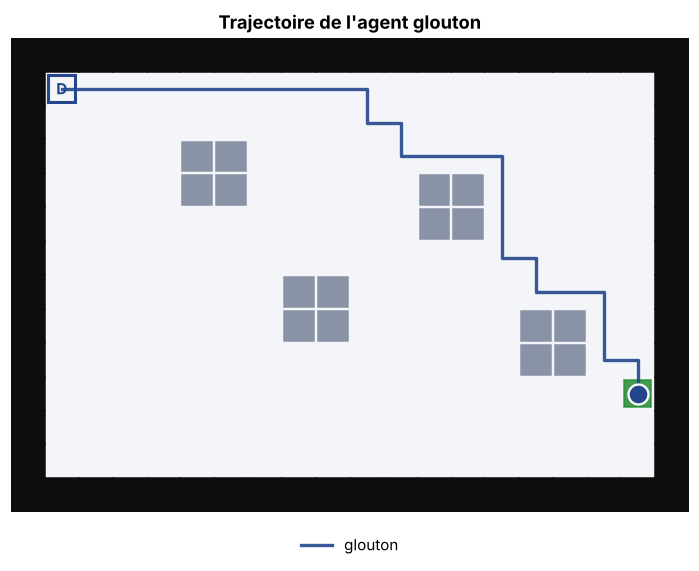

In [11]:
class AgentGlouton:
    """Va vers l'objectif si la voie est libre d'après le lidar, sinon choisit une direction libre au hasard."""

    nom = "glouton"

    def __init__(self, graine=0):
        self.graine = graine

    def reinitialiser(self, monde):
        self.rng = np.random.default_rng(self.graine)

    def lire(self, observation):
        """Lecture du capteur. Séparée de la décision pour pouvoir la modifier dans l'exercice 3."""
        return observation["lidar"]

    def decider(self, observation):
        lidar = self.lire(observation)
        dx, dy = observation["cap_objectif"]
        souhaits = []
        if dx != 0:
            souhaits.append("E" if dx > 0 else "O")
        if dy != 0:
            souhaits.append("S" if dy > 0 else "N")
        if abs(dy) > abs(dx):
            souhaits.reverse()
        for action in souhaits:
            if lidar[action] > 1:
                return action, {"raison": f"voie libre vers l'objectif : {action}"}
        libres = [a for a in ("N", "E", "S", "O") if lidar[a] > 1]
        if libres:
            action = str(self.rng.choice(libres))
            return action, {"raison": f"voie bloquée, essai au hasard : {action}"}
        return "ATTENDRE", {"raison": "aucune direction libre"}


PARAMETRES_BOUCLE = {"scenario": "ouvert", "etapes_affichees": 6, "max_etapes": 150}

monde = creer_scenario(PARAMETRES_BOUCLE["scenario"])
agent = AgentGlouton()
observation = monde.reinitialiser()
agent.reinitialiser(monde)
trajectoire = [monde.robot]
for t in range(PARAMETRES_BOUCLE["max_etapes"]):
    action, infos = agent.decider(observation)       # DÉCISION à partir de l'observation
    resultat = monde.avancer(action)                 # ACTION : l'environnement évolue
    observation = monde.observer()                   # PERCEPTION du nouvel état
    trajectoire.append(monde.robot)
    if t < PARAMETRES_BOUCLE["etapes_affichees"]:
        print(f"t={t}  action={action:8s} robot={monde.robot}  collision={resultat['collision']}  ({infos['raison']})")
    if resultat["arrive"]:
        break
print(f"...\nArrivé : {resultat['arrive']} en {t + 1} étapes, {monde.collisions} collision(s).")
dessiner_monde(monde, trajectoires={"glouton": trajectoire}, robot=monde.robot, titre="Trajectoire de l'agent glouton");

## 4. État réel et état observé

Jusqu'ici le lidar était parfait. Un capteur réel est bruité (`bruit_lidar`, écart type en cellules) et perd parfois un rayon (`perte_lidar`, probabilité de ne rien recevoir). L'agent ne décide jamais sur l'état réel : il décide sur une observation, qui peut être fausse.

         N  NE  E  SE  S  SO  O  NO
réel     1   1  6   2  6   1  1   1
observé  1   1  6   3  6   1  1   1
écart    0   0  0   1  0   0  0   0


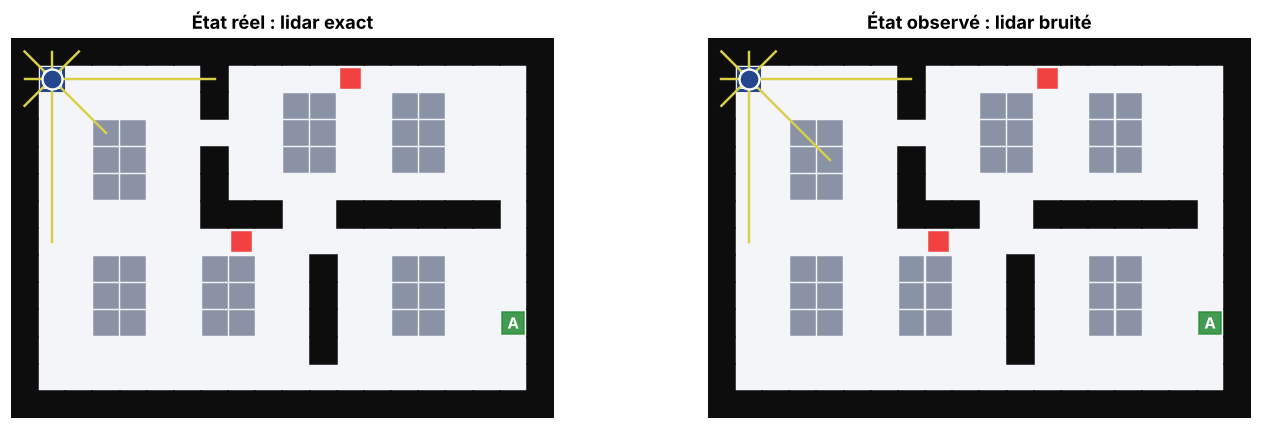

In [12]:
PARAMETRES_CAPTEUR = {"bruit_lidar": 0.6, "perte_lidar": 0.1, "graine": 4130}

monde = creer_scenario("entrepot", **PARAMETRES_CAPTEUR)
observation = monde.reinitialiser()
exact = monde.lidar_exact(monde.robot)
comparaison = pd.DataFrame({"réel": exact, "observé": observation["lidar"]})
comparaison["écart"] = comparaison["observé"] - comparaison["réel"]
print(comparaison.T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dessiner_monde(monde, axes[0], robot=monde.robot, lidar=exact, obstacles=monde.obstacles_dynamiques(), titre="État réel : lidar exact")
dessiner_monde(monde, axes[1], robot=monde.robot, lidar=observation["lidar"], obstacles=monde.obstacles_dynamiques(), titre="État observé : lidar bruité")
plt.tight_layout()

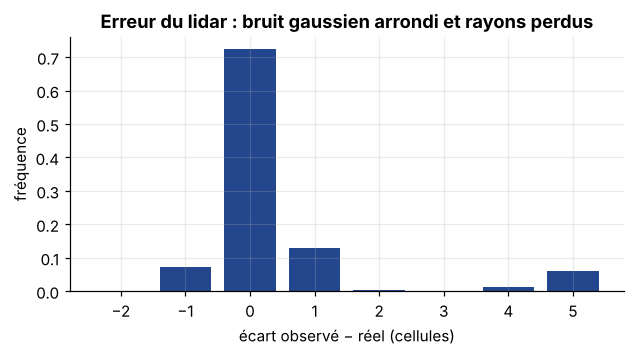

In [13]:
# Distribution de l'erreur de mesure sur 300 lectures au même endroit.
ecarts = []
for _ in range(300):
    mesure = monde.observer()["lidar"]
    ecarts += [mesure[r] - exact[r] for r in RAYONS]
valeurs, effectifs = np.unique(ecarts, return_counts=True)
plt.figure(figsize=(6.5, 3))
plt.bar(valeurs, effectifs / len(ecarts), color=BLEU)
plt.xlabel("écart observé − réel (cellules)")
plt.ylabel("fréquence")
plt.title("Erreur du lidar : bruit gaussien arrondi et rayons perdus");

**Conséquence sur le comportement.** L'agent glouton avance quand le lidar annonce une distance supérieure à 1. Si le capteur surestime la distance, il percute l'obstacle. Mesurons le nombre de collisions selon le niveau de bruit, sur plusieurs graines.

In [14]:
def campagne(fabrique_agent, bruits, graines=range(12), scenario="ouvert", **monde_kw):
    lignes = []
    for bruit in bruits:
        for g in graines:
            m = creer_scenario(scenario, bruit_lidar=bruit, graine=g, **monde_kw)
            bilan = simuler(m, fabrique_agent(g), max_etapes=150).bilan
            lignes.append({"bruit": bruit, "graine": g, **{k: bilan[k] for k in ("succes", "etapes", "collisions")}})
    return pd.DataFrame(lignes)


BRUITS = [0.0, 0.3, 0.6, 0.9, 1.2]
c_glouton = campagne(AgentGlouton, BRUITS)
resume = c_glouton.groupby("bruit")[["succes", "etapes", "collisions"]].mean().round(2)
resume

,succes,etapes,collisions
bruit,,,
0.0,1.0,26.00,0.00
0.3,1.0,26.33,0.33
0.6,1.0,27.00,1.00
0.9,1.0,27.33,1.17
1.2,1.0,27.50,1.17


### Exercice 3 : un agent plus prudent face au bruit

Proposez une parade et mesurez-la avec `campagne`. Piste : un robot réel répète souvent sa mesure. La classe `AgentGlouton` isole la lecture du capteur dans la méthode `lire` : il suffit de la redéfinir, par exemple en prenant la médiane de plusieurs lectures obtenues avec `self.monde.observer()`. Quel est le coût de cette parade dans un système réel ?

In [15]:
# À COMPLÉTER : pour l'instant, la lecture est identique à celle de l'agent glouton.
class AgentPrudent(AgentGlouton):
    nom = "prudent"

    def reinitialiser(self, monde):
        super().reinitialiser(monde)
        self.monde = monde

    def lire(self, observation):
        return observation["lidar"]


campagne(AgentPrudent, [0.9]).groupby("bruit")[["succes", "etapes", "collisions"]].mean().round(2)

,succes,etapes,collisions
bruit,,,
0.9,1.0,27.33,1.17


bruit,0.0,0.3,0.6,0.9,1.2
glouton,0.0,0.33,1.0,1.17,1.17
prudent,0.0,0.00,0.0,0.42,0.58


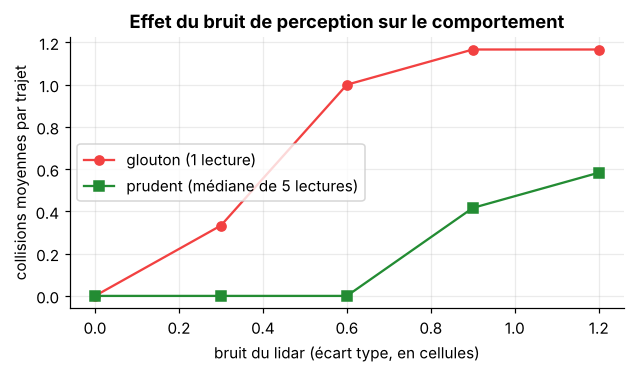

In [16]:
# Solution possible : médiane de k lectures successives.
class AgentPrudentSolution(AgentGlouton):
    nom = "prudent"
    lectures = 5

    def reinitialiser(self, monde):
        super().reinitialiser(monde)
        self.monde = monde

    def lire(self, observation):
        mesures = [observation["lidar"]] + [self.monde.observer()["lidar"] for _ in range(self.lectures - 1)]
        return {r: int(np.median([m[r] for m in mesures])) for r in RAYONS}


c_prudent = campagne(AgentPrudentSolution, BRUITS)
plt.figure(figsize=(6.5, 3.2))
plt.plot(BRUITS, c_glouton.groupby("bruit")["collisions"].mean(), "o-", color=ROUGE, label="glouton (1 lecture)")
plt.plot(BRUITS, c_prudent.groupby("bruit")["collisions"].mean(), "s-", color=VERT, label="prudent (médiane de 5 lectures)")
plt.xlabel("bruit du lidar (écart type, en cellules)")
plt.ylabel("collisions moyennes par trajet")
plt.title("Effet du bruit de perception sur le comportement")
plt.legend()
pd.DataFrame({"glouton": c_glouton.groupby("bruit")["collisions"].mean(), "prudent": c_prudent.groupby("bruit")["collisions"].mean()}).round(2).T

Répéter la mesure réduit les collisions, mais chaque lecture prend du temps et de l'énergie, et la médiane ne corrige pas un capteur biaisé. Le Jour 2 (module 5) introduit une réponse plus générale : maintenir une croyance probabiliste sur l'état.

## 5. Un environnement qui change : chariots et imprévus

L'entrepôt de référence contient deux chariots qui font des allers-retours. On peut aussi programmer un **événement** : une palette déposée sur une cellule à une étape donnée. L'environnement est alors dynamique : ce que l'agent a observé à l'étape précédente peut ne plus être vrai.

,sans palette,avec palettes
succes,True,True
etapes,26,26
distance,26,26
collisions,0,0


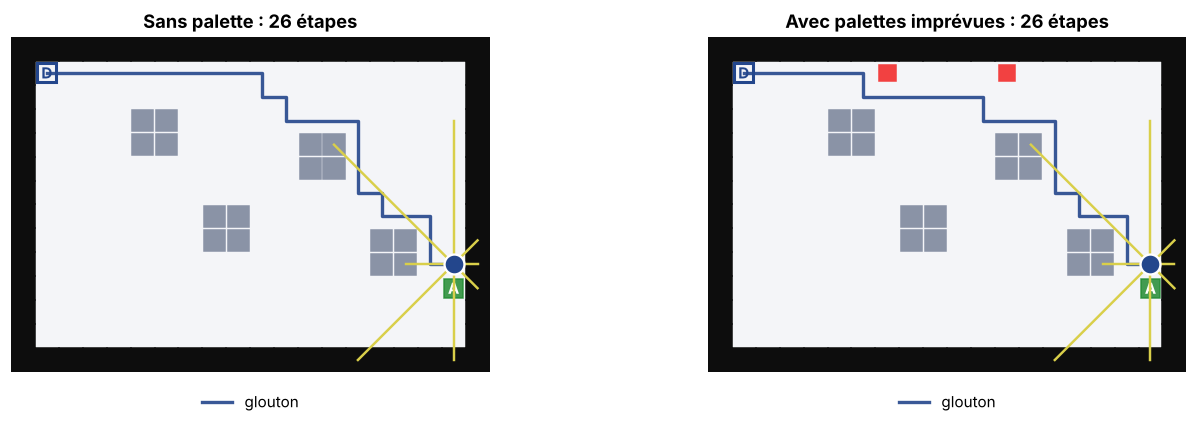

In [17]:
PARAMETRES_SCENARIO = {
    "scenario": "ouvert",
    "palettes": [(3, (7, 1)), (9, (12, 1))],   # (étape d'apparition, cellule), ici sur la route du robot
    "chariots": True,
    "graine_agent": 0,
}


def lancer(p, agent=None, **monde_kw):
    evenements = [Evenement(etape, cellule) for etape, cellule in p["palettes"]]
    monde = creer_scenario(p["scenario"], chariots=p["chariots"], evenements=evenements, **monde_kw)
    return simuler(monde, agent or AgentGlouton(p["graine_agent"]), max_etapes=150, module=2)


trace_sans = lancer({**PARAMETRES_SCENARIO, "palettes": []})
trace_avec = lancer(PARAMETRES_SCENARIO)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dessiner_trace(trace_sans, ax=axes[0], titre=f"Sans palette : {trace_sans.bilan['etapes']} étapes")
dessiner_trace(trace_avec, ax=axes[1], titre=f"Avec palettes imprévues : {trace_avec.bilan['etapes']} étapes")
plt.tight_layout()
pd.DataFrame({"sans palette": trace_sans.bilan, "avec palettes": trace_avec.bilan}).loc[["succes", "etapes", "distance", "collisions"]]

**Lecture.** Les palettes modifient la trajectoire sans l'allonger ici : quand la voie vers l'est se ferme, l'agent glouton descend vers le sud, ce qui le rapproche aussi de l'objectif. Dans un couloir étroit, le même imprévu l'aurait bloqué. Essayez avec le scénario `"entrepot"`.

## 6. La trace, format commun de rejeu

`simuler` exécute la boucle perception, décision, action et enregistre une **trace**. Ce format est commun à toute la formation : le même fichier JSON est produit par les notebooks et rejoué dans la scène 3D du site, étape par étape.

| Champ d'une étape | Contenu |
|---|---|
| `t` | Numéro d'étape |
| `etat` | État réel de l'environnement : robot, chariots, palettes |
| `observation` | Ce que l'agent a perçu : lidar, position mesurée |
| `decision` | Explication fournie par l'agent : raison, plan éventuel |
| `action` | Action choisie |
| `resultat` | Action exécutée, collision, arrivée, événements |
| `metriques` | Distance parcourue, collisions cumulées, temps de décision |

In [18]:
chemin = trace_avec.enregistrer(RESULTATS / "m2_glouton_palettes.json")
donnees = charger_trace(chemin)     # recharge et vérifie le schéma
print("Fichier :", chemin, f"({chemin.stat().st_size / 1024:.1f} Ko)")
print("Schéma  :", donnees["schema"])
print("Méta    :", donnees["meta"]["id"], "|", donnees["meta"]["agent"])
print("Bilan   :", {k: donnees["bilan"][k] for k in ("succes", "etapes", "collisions")})
print("\nÉtape 3 :")
for champ, valeur in donnees["etapes"][3].items():
    print(f"  {champ:12s} {json.dumps(valeur, ensure_ascii=False)}")

Fichier : resultats/m2_glouton_palettes.json (12.0 Ko)
Schéma  : ascent-4130-trace/1
Méta    : ouvert-glouton | glouton
Bilan   : {'succes': True, 'etapes': 26, 'collisions': 0}

Étape 3 :
  t            3
  etat         {"robot": [4, 1], "chariots": [], "palettes": [[7, 1]]}
  observation  {"lidar": {"N": 1, "NE": 1, "E": 3, "SE": 2, "S": 6, "SO": 4, "O": 4, "NO": 1}, "position": [4, 1]}
  decision     {"raison": "voie libre vers l'objectif : E"}
  action       "E"
  resultat     {"action_executee": "E", "glissement": false, "collision": false, "arrive": false, "evenements": []}
  metriques    {"distance": 4, "collisions": 0, "temps_decision_ms": 0.0006, "distance_objectif": 22}


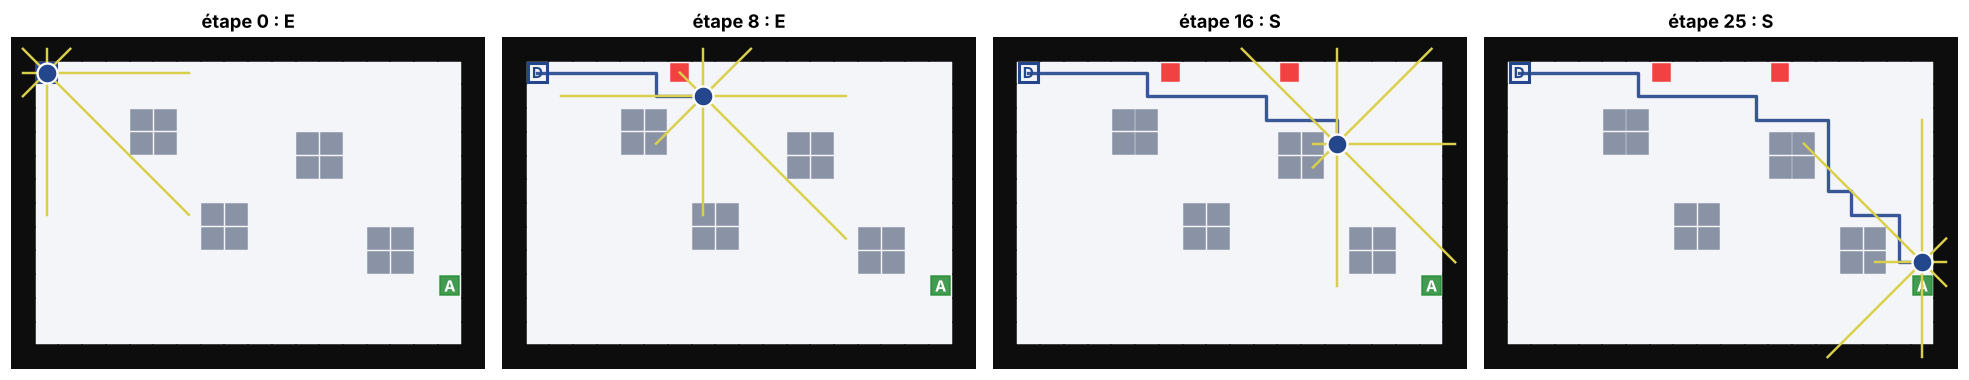

In [19]:
# Rejeu image par image à partir du fichier : exactement ce que fait la scène 3D du site.
instants = np.linspace(0, len(donnees["etapes"]) - 1, 4).astype(int)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, i in zip(axes, instants):
    dessiner_trace(donnees, int(i), ax=ax, titre=f"étape {i} : {donnees['etapes'][i]['action']}")
    ax.get_legend().remove()
plt.tight_layout()

### Exercice 4 (TP du syllabus) : simuler les interactions d'un agent dans un scénario donné

**Scénario imposé** : entrepôt de référence (`"entrepot"`), chariots actifs, une palette déposée à l'étape 5 en cellule (6, 3), lidar bruité (`bruit_lidar=0.4`).

1. Simulez l'agent glouton sur ce scénario pour les graines 0 à 9. Relevez le taux de réussite, le nombre d'étapes et les collisions.
2. Repérez dans une trace l'étape où l'agent rencontre la palette et lisez sa décision.
3. Modifiez l'agent (mémoire des cellules déjà visitées, lecture répétée du capteur, autre idée) et comparez.
4. Exportez votre meilleure trace dans `resultats/` pour la rejouer sur le site.

In [20]:
# À COMPLÉTER : point de départ fonctionnel avec l'agent glouton.
SCENARIO_TP = {"scenario": "entrepot", "palettes": [(5, (6, 3))], "chariots": True, "graine_agent": 0}

lignes = []
for g in range(10):
    trace = lancer(SCENARIO_TP, agent=AgentGlouton(g), bruit_lidar=0.4, graine=g)
    lignes.append({"graine": g, **{k: trace.bilan[k] for k in ("succes", "etapes", "collisions")}})
bilan_tp = pd.DataFrame(lignes)
print(bilan_tp[["succes", "etapes", "collisions"]].mean().round(2).to_dict())

{'succes': 0.5, 'etapes': 116.7, 'collisions': 11.3}


            glouton  mémoire
succes          0.5      1.0
etapes        116.7     41.6
collisions     11.3      0.2


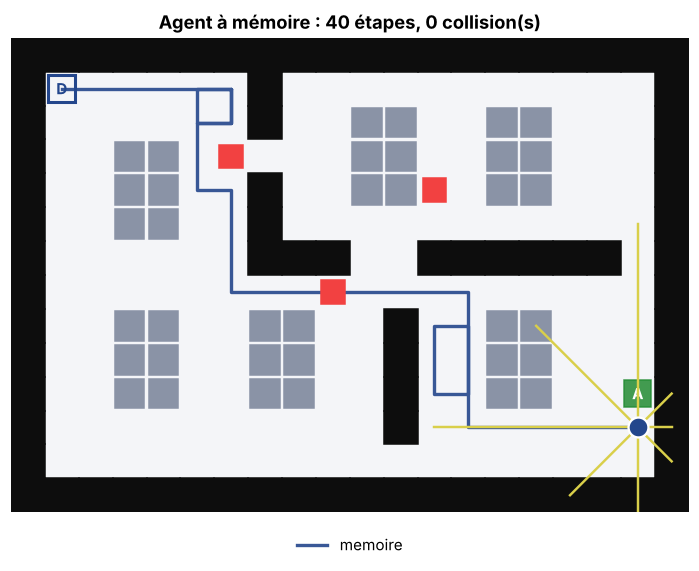

In [21]:
# Solution possible : lecture répétée du capteur et mémoire des cellules visitées (éviter de tourner en rond).
class AgentMemoire(AgentPrudentSolution):
    nom = "memoire"

    def reinitialiser(self, monde):
        super().reinitialiser(monde)
        self.visites = {}

    def decider(self, observation):
        lidar = self.lire(observation)
        x, y = observation["position"]
        self.visites[(x, y)] = self.visites.get((x, y), 0) + 1
        ox, oy = observation["objectif"]
        candidats = []
        for action in ("N", "E", "S", "O"):
            if lidar[action] > 1:
                dx, dy = ACTIONS[action]
                cible = (x + dx, y + dy)
                # Coût : distance restante à vol d'oiseau, plus une pénalité par passage déjà effectué.
                cout = abs(ox - cible[0]) + abs(oy - cible[1]) + 3 * self.visites.get(cible, 0)
                candidats.append((cout, action))
        if not candidats:
            return "ATTENDRE", {"raison": "aucune direction libre"}
        cout, action = min(candidats)
        return action, {"raison": f"cellule la moins coûteuse (coût {cout}) : {action}"}


lignes, meilleure = [], None
for g in range(10):
    trace = lancer(SCENARIO_TP, agent=AgentMemoire(g), bruit_lidar=0.4, graine=g)
    lignes.append({"graine": g, **{k: trace.bilan[k] for k in ("succes", "etapes", "collisions")}})
    if trace.bilan["succes"] and (meilleure is None or trace.bilan["etapes"] < meilleure.bilan["etapes"]):
        meilleure = trace
bilan_memoire = pd.DataFrame(lignes)
comparaison = pd.DataFrame({"glouton": bilan_tp[["succes", "etapes", "collisions"]].mean(),
                            "mémoire": bilan_memoire[["succes", "etapes", "collisions"]].mean()}).round(2)
print(comparaison)
if meilleure is not None:
    meilleure.enregistrer(RESULTATS / "m2_tp_agent_memoire.json")
    dessiner_trace(meilleure, titre=f"Agent à mémoire : {meilleure.bilan['etapes']} étapes, {meilleure.bilan['collisions']} collision(s)")

L'agent à mémoire garde un état interne (les cellules visitées) : il n'est plus purement réactif. Cette frontière entre agents sans mémoire, agents à modèle et agents qui planifient est l'objet du module 3.

## Synthèse du module

- Un agent se définit par sa boucle : percevoir par des capteurs, décider, agir par des effecteurs, puis recommencer.
- Un environnement simulé fournit trois éléments : un état, une fonction d'observation et une fonction de transition.
- L'agent ne décide jamais sur l'état réel mais sur une observation, bruitée et partielle. Le bruit de perception se traduit directement en collisions.
- Un environnement dynamique (chariots, palettes imprévues) rend périmée une partie de ce qui vient d'être observé.
- La trace d'exécution (état, observation, décision, action, résultat, métriques) rend chaque comportement rejouable et comparable, du notebook à la scène 3D.